In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from scipy import signal

Mpc_conversion=1.065e-30

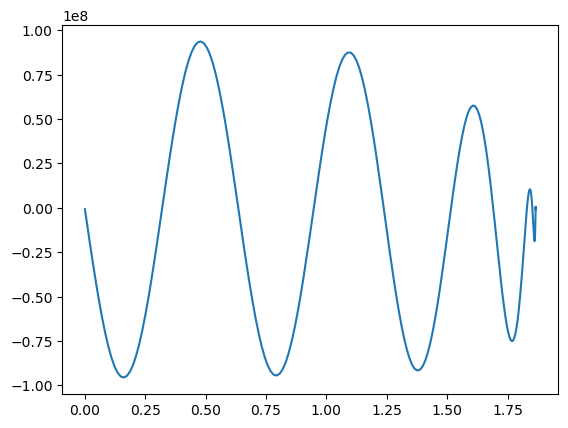

In [3]:
df = pd.read_csv('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv')
plt.plot(df['t'],df['ddI_xx'])

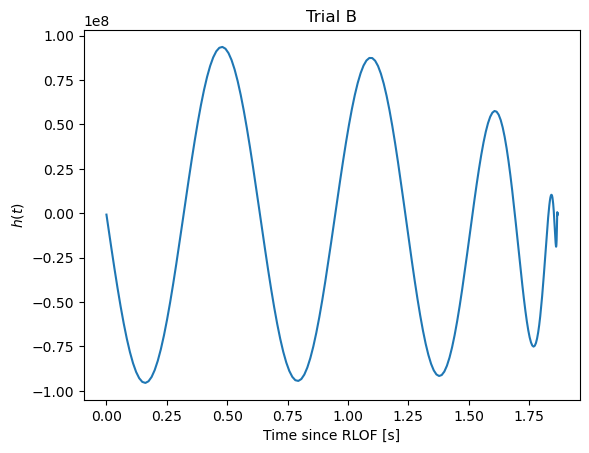

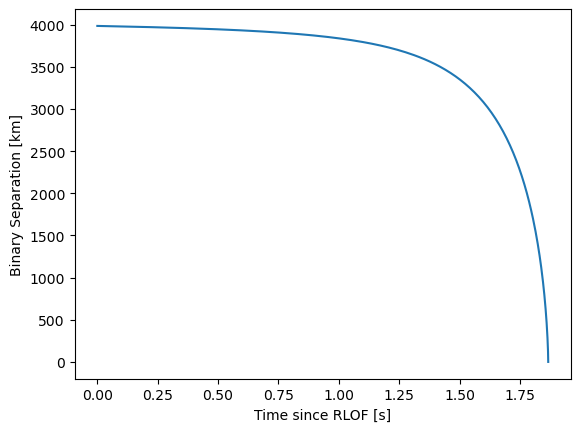

ValueError: 
$M_{m WD} (M_\odot)$
^
ParseException: Expected end of text, found '$'  (at char 0), (line:1, col:1)

<Figure size 640x480 with 1 Axes>

In [11]:
df = pd.read_csv('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv')
plt.title("Trial B")
plt.plot(df['t'],df['ddI_xx'])
plt.xlabel("Time since RLOF [s]")
plt.ylabel("$h(t)$")
plt.show()
plt.plot(df['t'],df['a'])
plt.xlabel("Time since RLOF [s]")
plt.ylabel("Binary Separation [km]")
plt.show()
plt.plot(df['t'][df['M_WD']>0.01],df['M_WD'][df['M_WD']>0.01])
plt.xlabel("Time since RLOF [s]")
plt.ylabel("$M_{\rm WD} (M_\odot)$")
plt.show()

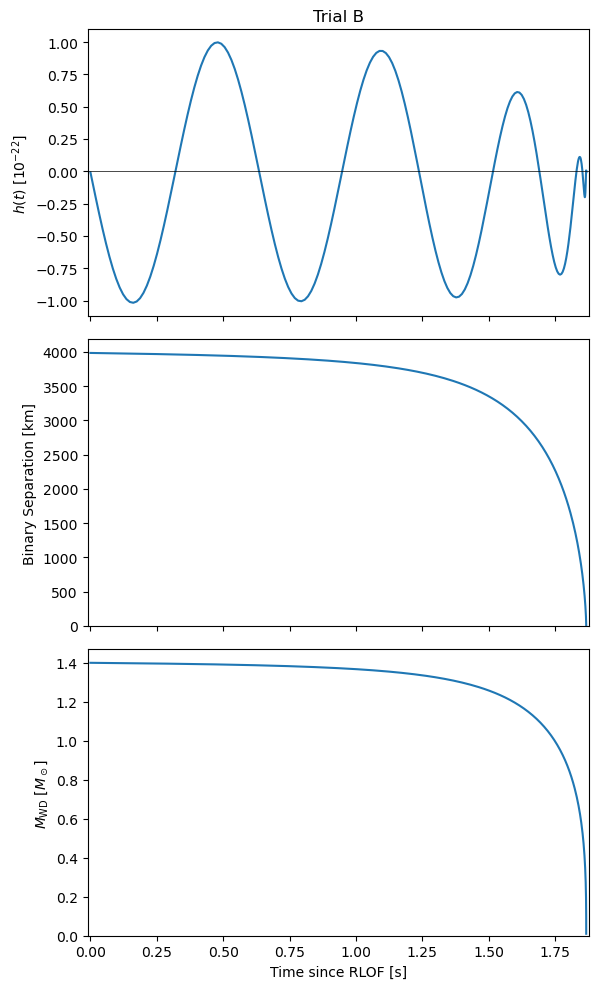

In [32]:
fig, axes = plt.subplots(3, 1, figsize=(6, 10), sharex=True)

# --- Top panel: h(t)
axes[0].plot(df['t'], df['ddI_xx']*1.065e-30*1e22)
axes[0].set_ylabel(r"$h(t)\ [10^{-22}]$ ")
axes[0].set_title("Trial B")
axes[0].axhline(0,c="k",linewidth=0.5)
axes[0].set_xlim(-0.01,max(df['t'])+0.01)

# --- Middle panel: separation a(t)
axes[1].plot(df['t'], df['a'])
axes[1].set_ylabel("Binary Separation [km]")
axes[1].set_ylim(0,axes[1].get_ylim()[-1])

# --- Bottom panel: WD mass vs time
mask = df['M_WD'] > 0.01
axes[2].plot(df['t'][mask], df['M_WD'][mask])
axes[2].set_ylabel(r"$M_{\rm WD}\ [M_\odot]$")
axes[2].set_xlabel("Time since RLOF [s]")
axes[2].set_ylim(0,axes[2].get_ylim()[-1])

plt.tight_layout()
plt.show()

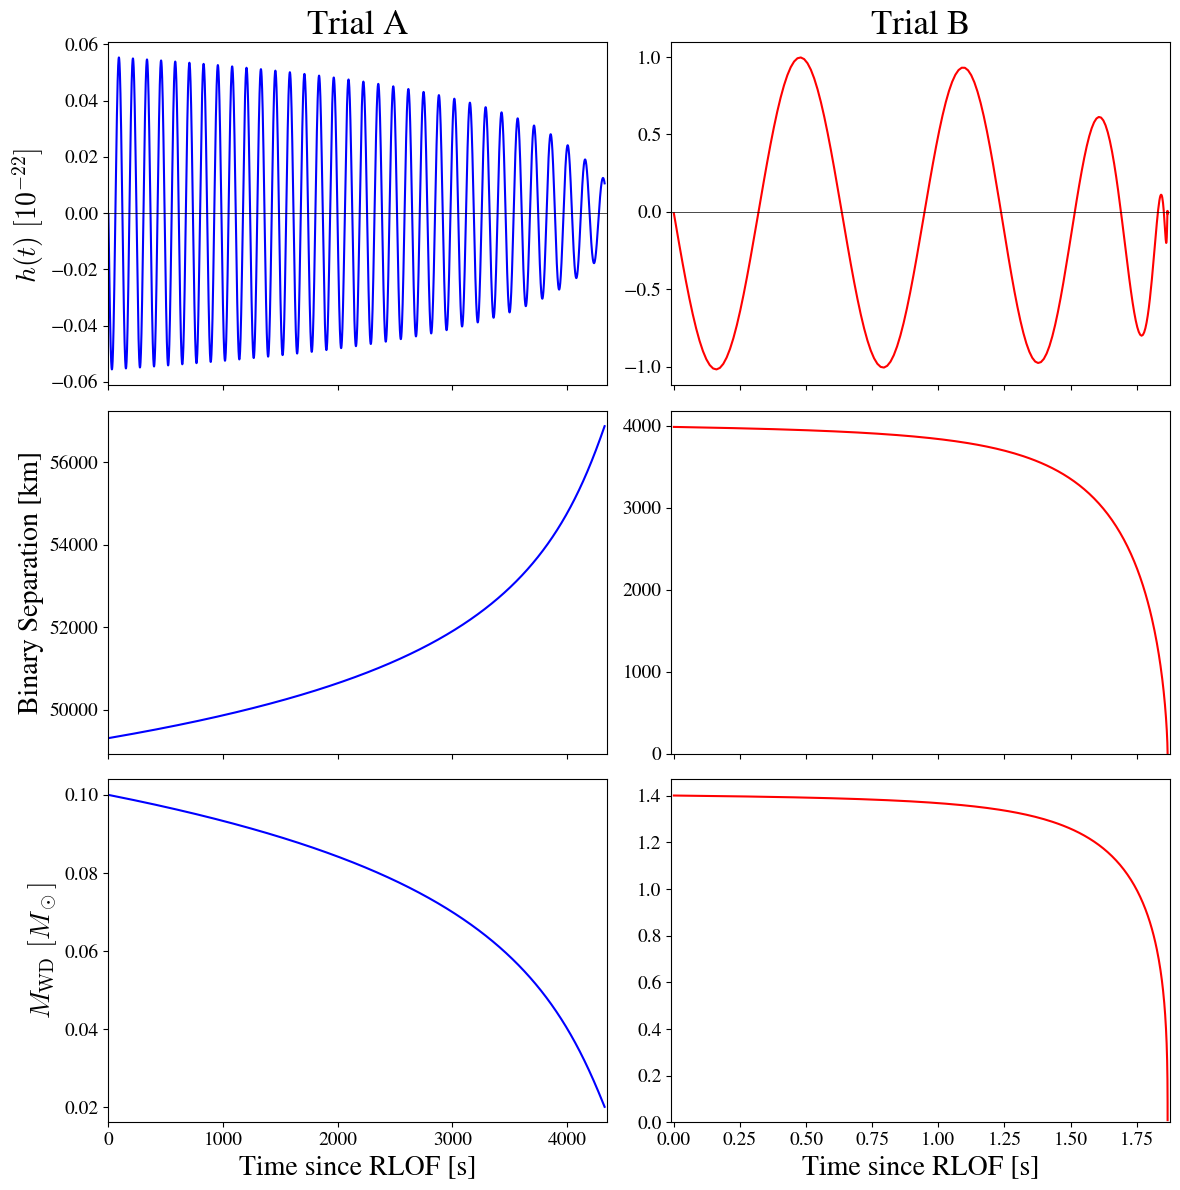

In [53]:


plt.rcParams.update({
    "text.usetex": False,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})

plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["mathtext.rm"] = "serif"

fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex='col')

for a in axes.flat:
    a.tick_params(axis='both', labelsize=14)




df = pd.read_csv('20251202_M_WD=0.1_M_NS=0.5_A=10.0_6.csv')

mask = np.ones(len(df['t']), dtype=bool)
mask[499::500] = False

axes[0,0].plot(df['t'][mask], df['ddI_xx'][mask]*1.065e-30*1e22,c="b")
axes[0,0].set_ylabel(r"$h(t)\ [10^{-22}]$ ",size=20)
axes[0,0].set_title("Trial A",size=25)
axes[0,0].axhline(0,c="k",linewidth=0.5)
axes[0,0].set_xlim(-0.01,max(df['t'])+25)

# --- Middle panel: separation a(t)
axes[1,0].plot(df['t'][mask], df['a'][mask],c="b")
axes[1,0].set_ylabel("Binary Separation [km]",size=20)
#axes[1,0].set_ylim(0,axes[1,0].get_ylim()[-1])

# --- Bottom panel: WD mass vs time
axes[2,0].plot(df['t'][mask], df['M_WD'][mask],c="b")
axes[2,0].set_ylabel(r"$M_{\rm WD}\ [M_\odot]$",size=20)
axes[2,0].set_xlabel("Time since RLOF [s]",size=20)
#axes[2,0].set_ylim(0,axes[2,0].get_ylim()[-1])






df = pd.read_csv('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv')
axes[0,1].plot(df['t'], df['ddI_xx']*1.065e-30*1e22,c="r")
#axes[1,0].set_ylabel(r"$h(t)\ [10^{-22}]$ ")
axes[0,1].set_title("Trial B",size=25)
axes[0,1].axhline(0,c="k",linewidth=0.5)
axes[0,1].set_xlim(-0.01,max(df['t'])+0.01)

# --- Middle panel: separation a(t)
axes[1,1].plot(df['t'], df['a'],c="r")
#axes[1,1].set_ylabel("Binary Separation [km]")
axes[1,1].set_ylim(0,axes[1,1].get_ylim()[-1])

# --- Bottom panel: WD mass vs time
axes[2,1].plot(df['t'], df['M_WD'],c="r")
#axes[1,2].set_ylabel(r"$M_{\rm WD}\ [M_\odot]$")
axes[2,1].set_xlabel("Time since RLOF [s]",size=20)
axes[2,1].set_ylim(0,axes[2,1].get_ylim()[-1])

plt.tight_layout()
plt.savefig("Trial_A_B.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [4]:
fs_max=np.zeros([3,4,3,3])
hcs_max=np.zeros([3,4,3,3])

for i,M_WD in enumerate(["1.0", "1.3", "1.4"]):
    for j,M_NS in enumerate(["3.0", "10.0", "30.0", "100.0"]):
        for k,A in enumerate(["3.0", "10.0", "30.0"]):
            for l,mode in enumerate(["Iso", "Jeans", "CR"]):
                try:
                    t_f,t_hc=calc_hc('20251203_M_WD='+M_WD+'_M_NS='+M_NS+'_A='+A+'_mode='+mode+'.csv')
                    fs_max[i,j,k,l]=t_f
                    hcs_max[i,j,k,l]=t_hc
                except:
                    print('20251203_M_WD='+M_WD+'_M_NS='+M_NS+'_A='+A+'_mode='+mode+'.csv')
                    fs_max[i,j,k,l]=-1
                    hcs_max[i,j,k,l]=-1

                

20251203_M_WD=1.0_M_NS=3.0_A=30.0_mode=CR.csv
20251203_M_WD=1.4_M_NS=3.0_A=30.0_mode=Jeans.csv
20251203_M_WD=1.4_M_NS=3.0_A=30.0_mode=CR.csv


In [111]:
fs_max

array([[[[ 0.13147871,  0.13687132,  0.13920305],
         [ 0.13170615,  0.13659415,  0.13791347],
         [ 0.13016959,  0.14356621, -1.        ]],

        [[ 0.21655427,  0.25733812,  0.29210575],
         [ 0.20306655,  0.31863804,  0.36325812],
         [ 0.25852185,  0.43977359,  0.50596802]],

        [[ 0.37016593,  0.54969392,  0.57590378],
         [ 0.35866776,  0.86441898,  0.90825026],
         [ 0.61467906,  2.51210154,  2.64549465]],

        [[ 0.65295219,  1.97882125,  1.00433737],
         [ 0.97253816,  3.23073281,  3.28098216],
         [ 0.88482396,  9.6161055 ,  9.76757732]]],


       [[[ 0.3603083 ,  0.36602331,  0.36874019],
         [ 0.35909345,  0.3669092 ,  0.37044523],
         [ 0.36059779,  0.36735468,  0.37190089]],

        [[ 0.55143954,  0.66062712,  0.74444329],
         [ 0.55537506,  0.76356944,  0.86566937],
         [ 0.79878268,  0.9647929 ,  1.1076405 ]],

        [[ 0.98643466,  1.38821748,  1.46058021],
         [ 1.03438721,  2.02472874, 

In [32]:
for i in range(3):
    print(np.mean(fs_max[i][hcs_max[i]!=-1]))
print("")
for i in range(4):
    print(np.mean(fs_max[:,i][hcs_max[:,i]!=-1]))

1.2780278157880596
3.0455108693681563
8.296054274201563

0.464541376562359
1.1509524954478392
3.5491401507944493
11.051248729135203


In [31]:
for i in range(3):
    print(np.mean(hcs_max[i][hcs_max[i]!=-1]))
print("")
for i in range(4):
    print(np.mean(hcs_max[:,i][hcs_max[:,i]!=-1]))

5.606282017178258e-22
6.844381434550408e-22
3.6229602733973337e-22

1.5018736582524962e-21
1.744570478077601e-22
1.8230093515422337e-22
4.0379228948232745e-22


In [34]:
for i in range(3):
    for j in range(4):
        print(i,j,np.mean(hcs_max[i,j][hcs_max[i,j]!=-1]))
    print("")

0 0 1.4000338852387356e-21
0 1 2.322753869191266e-22
0 2 2.2415000359879484e-22
0 3 4.793208292836359e-22

1 0 1.9397099727138882e-21
1 1 1.9212045702214451e-22
1 2 1.9045974597947117e-22
1 3 4.15462398104659e-22

2 0 1.055329565960718e-21
2 1 9.897529948200916e-23
2 2 1.3229305588440413e-22
2 3 3.165936410586875e-22



In [39]:
for i in range(3):
    for j in range(4):
        for k in range(3):
            for l in range(3):
                if fs_max[i,j,k,l]>8:
                    print(i,j,k,l)
                    print(hcs_max[i,j,k,l]/np.interp(fs_max[i,j,k,l],
                                   LIGO_full[::2],
                                   LIGO_full[1::2]))

0 3 2 1
0.7988201943428388
0 3 2 2
0.4322856728411536
1 3 2 1
10.243213735717543
1 3 2 2
10.685715556568386
2 2 2 1
1.1225264628323184
2 2 2 2
1.293887105760085
2 3 1 1
3.113897951770254
2 3 1 2
3.2574734353930594
2 3 2 1
17.433179802136205
2 3 2 2
17.840550614412532


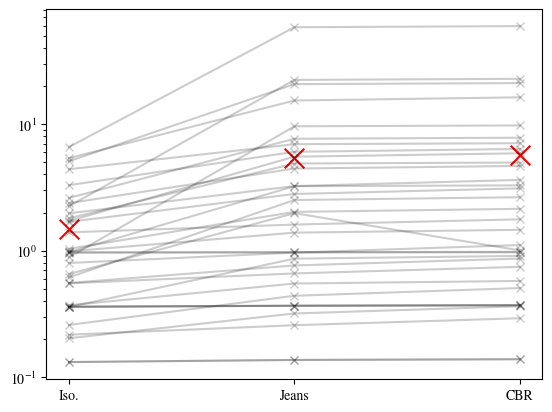

([<matplotlib.axis.XTick at 0x14ece804f590>,
 [Text(1, 0, 'Iso.'), Text(2, 0, 'Jeans'), Text(3, 0, 'CBR')])

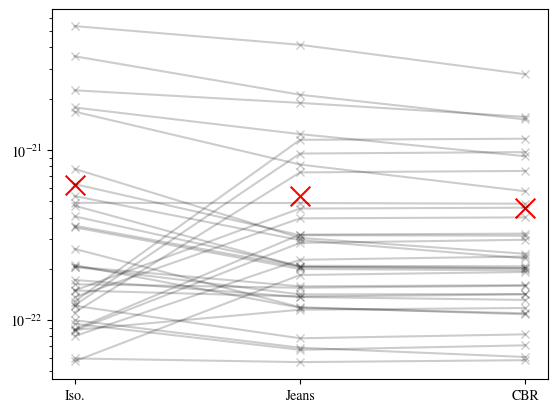

In [58]:
for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,k]: 
                plt.plot([1,2,3],fs_max[i,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[:,:,:,i][hcs_max[:,:,:,i]!=-1]))

    
plt.scatter([1,2,3],t_fs,c="r",marker="x",s=200)
plt.yscale("log")
plt.xticks([1,2,3],["Iso.", "Jeans", "CBR"])

plt.show()




for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,k]: 
                plt.plot([1,2,3],hcs_max[i,j,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[:,:,:,i][hcs_max[:,:,:,i]!=-1]))

    
plt.scatter([1,2,3],t_hcs,c="r",marker="x",s=200)
plt.yscale("log")
plt.xticks([1,2,3],["Iso.", "Jeans", "CBR"])

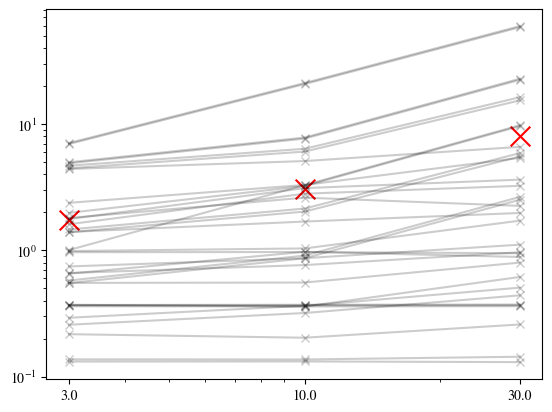

([<matplotlib.axis.XTick at 0x14ece6d35e90>,
 [Text(3, 0, '3.0'), Text(10, 0, '10.0'), Text(30, 0, '30.0')])

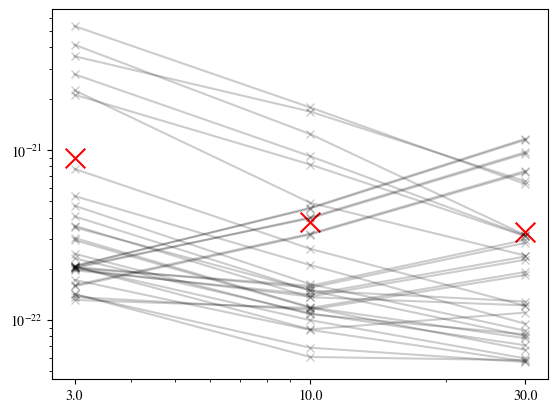

In [62]:
for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,:,k]: 
                plt.plot([3,10,30],fs_max[i,j,:,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[:,:,i][hcs_max[:,:,i]!=-1]))

    
plt.scatter([3,10,30],t_fs,c="r",marker="x",s=200)
plt.yscale("log")
plt.xscale("log")
plt.xticks([3,10,30],["3.0","10.0","30.0"])

plt.show()




for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,:,k]: 
                plt.plot([3,10,30],hcs_max[i,j,:,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[:,:,i][hcs_max[:,:,i]!=-1]))

    
plt.scatter([3,10,30],t_hcs,c="r",marker="x",s=200,alpha=1)
plt.yscale("log")
plt.xscale("log")
plt.xticks([3,10,30],["3.0","10.0","30.0"])

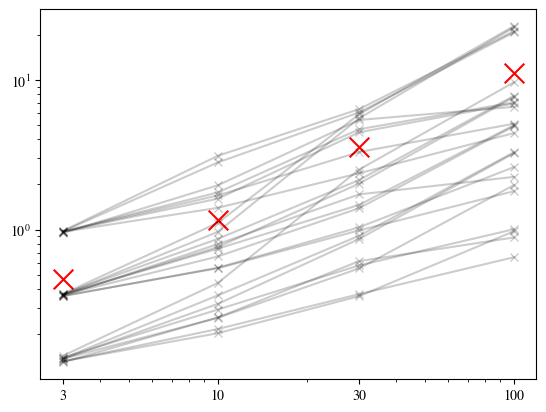

([<matplotlib.axis.XTick at 0x14ece590ec10>,
 [Text(3, 0, '3'), Text(10, 0, '10'), Text(30, 0, '30'), Text(100, 0, '100')])

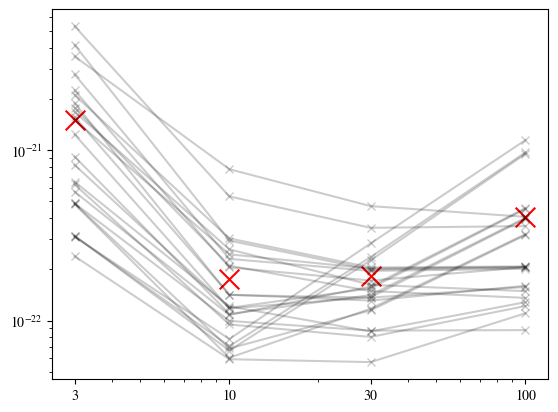

In [65]:
for i in range(3):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[i,:,j,k]: 
                plt.plot([3,10,30,100],fs_max[i,:,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(4):
    t_fs.append(np.mean(fs_max[:,i][hcs_max[:,i]!=-1]))

    
plt.scatter([3,10,30,100],t_fs,c="r",marker="x",s=200)
plt.yscale("log")
plt.xscale("log")
plt.xticks([3,10,30,100],["3","10","30","100"])

plt.show()




for i in range(3):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[i,:,j,k]: 
                plt.plot([3,10,30,100],hcs_max[i,:,j,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(4):
    t_hcs.append(np.mean(hcs_max[:,i][hcs_max[:,i]!=-1]))

    
plt.scatter([3,10,30,100],t_hcs,c="r",marker="x",s=200,alpha=1)
plt.yscale("log")
plt.xscale("log")
plt.xticks([3,10,30,100],["3","10","30","100"])

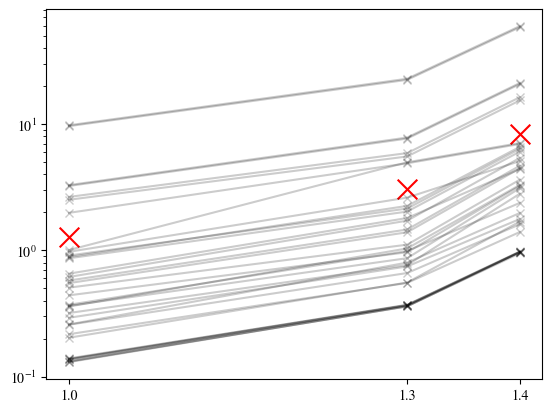

([<matplotlib.axis.XTick at 0x14ece718ca10>,
 [Text(1.0, 0, '1.0'), Text(1.3, 0, '1.3'), Text(1.4, 0, '1.4')])

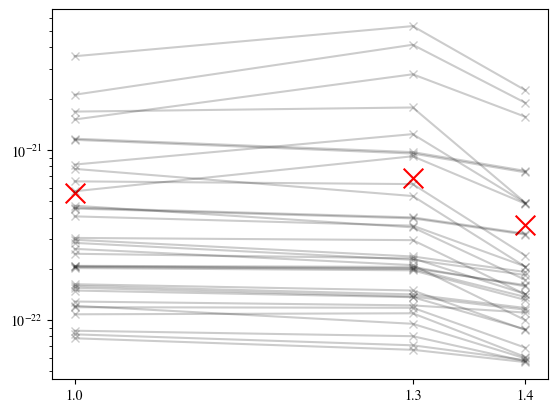

In [70]:
for i in range(4):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[:,i,j,k]: 
                plt.plot([1,1.3,1.4],fs_max[:,i,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[i][hcs_max[i]!=-1]))

    
plt.scatter([1,1.3,1.4],t_fs,c="r",marker="x",s=200)
plt.yscale("log")
plt.xticks([1,1.3,1.4])





for i in range(4):
    for j in range(3):
        for k in range(3):
            if not(i==0 and j==2 and (k==1 or k==2)): 
                plt.plot([1,1.3,1.4],hcs_max[:,i,j,k],c="k",alpha=0.2,marker="x")
                #print(i,j,k,hcs_max[:,i,j,k])
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[i][hcs_max[i]!=-1]))

    
plt.scatter([1,1.3,1.4],t_hcs,c="r",marker="x",s=200,alpha=1)
plt.yscale("log")
plt.xticks([1,1.3,1.4])

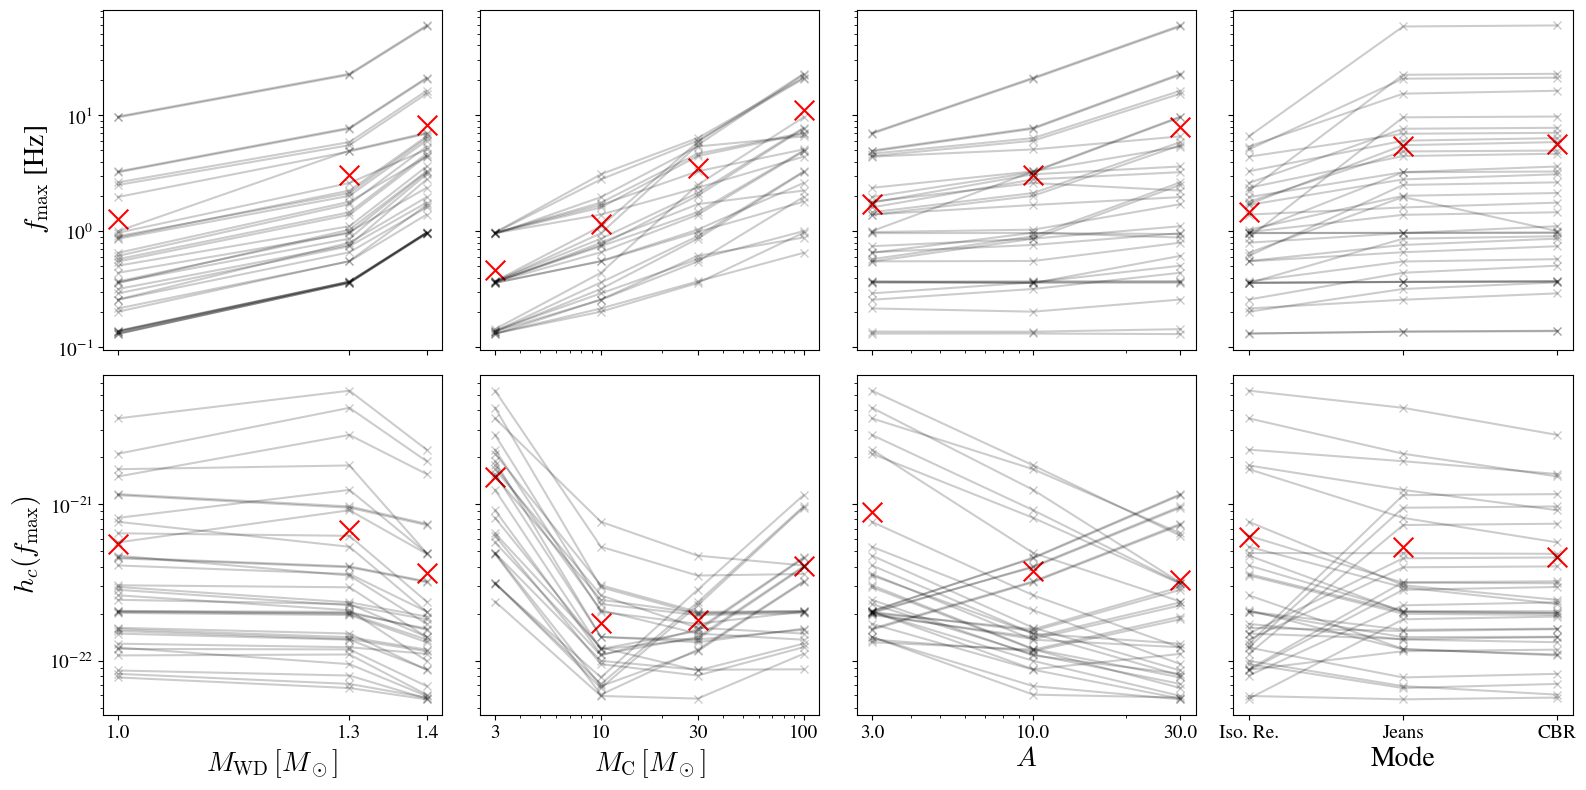

In [86]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    2, 4,
    figsize=(16, 8),
    sharex='col',   # each column shares its x-axis
    sharey='row'    # each row shares its y-axis
)


for a in ax.flat:
    a.tick_params(axis='both', labelsize=14)


#MWD ------------------------------------------------------

for i in range(4):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[:,i,j,k]: 
                ax[0,0].plot([1,1.3,1.4],fs_max[:,i,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[i][hcs_max[i]!=-1]))

    
ax[0,0].scatter([1,1.3,1.4],t_fs,c="r",marker="x",s=200)
ax[0,0].set_yscale("log")
ax[0,0].set_xticks([1,1.3,1.4])





for i in range(4):
    for j in range(3):
        for k in range(3):
            if not(i==0 and j==2 and (k==1 or k==2)): 
                ax[1,0].plot([1,1.3,1.4],hcs_max[:,i,j,k],c="k",alpha=0.2,marker="x")
                #print(i,j,k,hcs_max[:,i,j,k])
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[i][hcs_max[i]!=-1]))

    
ax[1,0].scatter([1,1.3,1.4],t_hcs,c="r",marker="x",s=200,alpha=1)
ax[1,0].set_yscale("log")
ax[1,0].set_xticks([1,1.3,1.4])

#M_C


for i in range(3):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[i,:,j,k]: 
                ax[0,1].plot([3,10,30,100],fs_max[i,:,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(4):
    t_fs.append(np.mean(fs_max[:,i][hcs_max[:,i]!=-1]))

    
ax[0,1].scatter([3,10,30,100],t_fs,c="r",marker="x",s=200)
ax[0,1].set_yscale("log")
ax[0,1].set_xscale("log")
ax[0,1].set_xticks([3,10,30,100],["3","10","30","100"])




for i in range(3):
    for j in range(3):
        for k in range(3):
            if -1 not in fs_max[i,:,j,k]: 
                ax[1,1].plot([3,10,30,100],hcs_max[i,:,j,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(4):
    t_hcs.append(np.mean(hcs_max[:,i][hcs_max[:,i]!=-1]))

    
ax[1,1].scatter([3,10,30,100],t_hcs,c="r",marker="x",s=200,alpha=1)
ax[1,1].set_yscale("log")
ax[1,1].set_xscale("log")
ax[1,1].set_xticks([3,10,30,100],["3","10","30","100"])



# A


for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,:,k]: 
                ax[0,2].plot([3,10,30],fs_max[i,j,:,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[:,:,i][hcs_max[:,:,i]!=-1]))

    
ax[0,2].scatter([3,10,30],t_fs,c="r",marker="x",s=200)
ax[0,2].set_yscale("log")
ax[0,2].set_xscale("log")
ax[0,2].set_xticks([3,10,30],["3.0","10.0","30.0"])






for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,:,k]: 
                ax[1,2].plot([3,10,30],hcs_max[i,j,:,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[:,:,i][hcs_max[:,:,i]!=-1]))

    
ax[1,2].scatter([3,10,30],t_hcs,c="r",marker="x",s=200,alpha=1)
ax[1,2].set_yscale("log")
ax[1,2].set_xscale("log")
ax[1,2].set_xticks([3,10,30],["3.0","10.0","30.0"])



#Mode
for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,k]: 
                ax[0,3].plot([1,2,3],fs_max[i,j,k],c="k",alpha=0.2,marker="x")


t_fs=[]
for i in range(3):
    t_fs.append(np.mean(fs_max[:,:,:,i][hcs_max[:,:,:,i]!=-1]))

    
ax[0,3].scatter([1,2,3],t_fs,c="r",marker="x",s=200)
ax[0,3].set_yscale("log")
ax[0,3].set_xticks([1,2,3],["Iso.", "Jeans", "CBR"])






for i in range(3):
    for j in range(4):
        for k in range(3):
            if -1 not in fs_max[i,j,k]: 
                ax[1,3].plot([1,2,3],hcs_max[i,j,k],c="k",alpha=0.2,marker="x")
           

t_hcs=[]
for i in range(3):
    t_hcs.append(np.mean(hcs_max[:,:,:,i][hcs_max[:,:,:,i]!=-1]))

    
ax[1,3].scatter([1,2,3],t_hcs,c="r",marker="x",s=200)
ax[1,3].set_yscale("log")
ax[1,3].set_xticks([1,2,3],["Iso. Re.", "Jeans", "CBR"])






ax[0,0].set_ylabel(r"$f_{\rm max}$ [Hz]",size=20)
ax[1,0].set_ylabel(r"$h_c(f_{\rm max})$",size=20)

ax[1,0].set_xlabel(r"$M_{\rm WD}\,[M_\odot]$",size=20)
ax[1,1].set_xlabel(r"$M_{\rm C}\,[M_\odot]$",size=20)
ax[1,2].set_xlabel(r"$A$",size=20)
ax[1,3].set_xlabel(r"Mode",size=20)

plt.tight_layout()

plt.savefig("Param_Dependences.pdf", dpi=300, bbox_inches="tight")

In [37]:
LIGO_full

array([5.03197811e+00, 4.47251304e-20, 5.16011003e+00, 3.37369335e-20,
       5.36272680e+00, 2.19708054e-20, 5.57532569e+00, 1.49174615e-20,
       5.76740659e+00, 1.00983496e-20, 5.93805200e+00, 7.43058539e-21,
       6.17613731e+00, 5.07526725e-21, 6.47382119e+00, 3.42547596e-21,
       6.75687575e+00, 2.29140852e-21, 7.05230630e+00, 1.60282522e-21,
       7.43982480e+00, 1.06687118e-21, 8.11644348e+00, 7.25810494e-22,
       8.69992542e+00, 6.55285050e-22, 9.21051566e+00, 7.80328347e-22,
       9.64048043e+00, 1.47260105e-21, 9.80000000e+00, 3.00000000e-21,
       9.80000000e+00, 9.60000000e-20, 9.80000000e+00, 3.00000000e-21,
       1.02553848e+01, 5.80082352e-22, 1.07267079e+01, 3.82584412e-22,
       1.19124277e+01, 2.65926913e-22, 1.41364776e+01, 1.84978256e-22,
       1.69561969e+01, 1.36426689e-22, 2.10017082e+01, 9.92356999e-23,
       2.65750079e+01, 7.31781237e-23, 3.36273146e+01, 5.69655418e-23,
       4.25511175e+01, 4.75147198e-23, 5.38430626e+01, 4.28111343e-23,
      

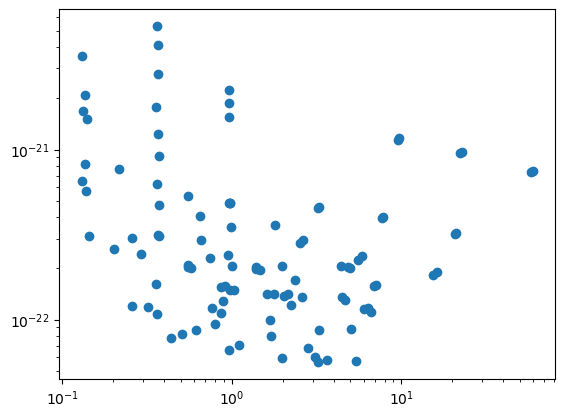

In [14]:
plt.scatter(fs_max.flatten(),hcs_max.flatten())
plt.xscale("log")
plt.yscale("log")
lims_all_pts_x=plt.xlim()
lims_all_pts_y=plt.ylim()

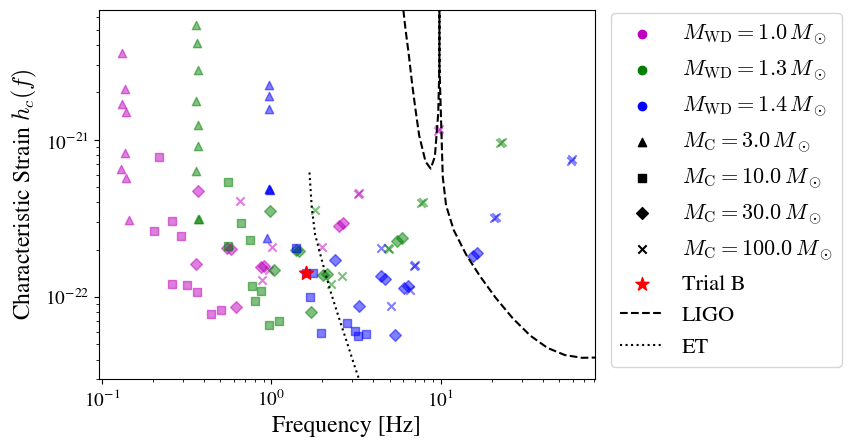

In [21]:
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})

plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["mathtext.rm"] = "serif"
plt.xlabel("Frequency [Hz]",size=17)
plt.ylabel("Characteristic Strain $h_c(f)$",size=17)


cs=["m","g","b"]
ss=["^","s","D","x"]


for i in range(3):
    for j in range(4):
        plt.scatter(fs_max[i,j].flatten(),hcs_max[i,j].flatten(),c=cs[i],marker=ss[j],alpha=0.5)

plt.scatter([1.606981595370176], [1.41270422908376e-22],c="r",marker="*",s=100)
plt.xscale("log")
plt.yscale("log")



plt.scatter([],[],c="m",marker="o",label=r"$M_{\rm WD}=1.0\,M_\odot$")
plt.scatter([],[],c="g",marker="o",label=r"$M_{\rm WD}=1.3\,M_\odot$")
plt.scatter([],[],c="b",marker="o",label=r"$M_{\rm WD}=1.4\,M_\odot$")

plt.scatter([],[],c="k",marker="^",label=r"$M_{\rm C}=3.0\,M_\odot$")
plt.scatter([],[],c="k",marker="s",label=r"$M_{\rm C}=10.0\,M_\odot$")
plt.scatter([],[],c="k",marker="D",label=r"$M_{\rm C}=30.0\,M_\odot$")
plt.scatter([],[],c="k",marker="x",label=r"$M_{\rm C}=100.0\,M_\odot$")

plt.scatter([1.606981595370176], [1.41270422908376e-22],c="r",marker="*",s=100,label="Trial B")

#plt.loglog(LISA[::2],LISA[1::2],c="k",label="LISA")
plt.loglog(LIGO_full[::2],LIGO_full[1::2],c="k",linestyle="--",label="LIGO")




plt.loglog(ET2[::2],ET2[1::2],c="k",linestyle=":",label="ET")
#plt.loglog(CE2[::2],CE2[1::2],c="k",linestyle=(0, (5, 5, 1, 1, 1, 5)),label="ET")
#plt.loglog(DECIGO[::2],DECIGO[1::2],linestyle="-.",label="DECIGO",c="k")
plt.xlim(lims_all_pts_x)
plt.ylim(3e-23,lims_all_pts_y[1])


plt.legend(bbox_to_anchor=(1.01, 1.02), loc='upper left',fontsize=16)



plt.tick_params(axis='both', labelsize=14)

plt.savefig("hc_heavies.pdf", dpi=300, bbox_inches="tight")


#bbox_to_anchor=(1.01, 1.02), loc='upper left',fontsize=16



#plt.legend(bbox_to_anchor=(1.01, 0.75), handles=marker_handles, title="Black Hole Mass",
#           loc="upper right",fontsize=16,title_fontsize=16)

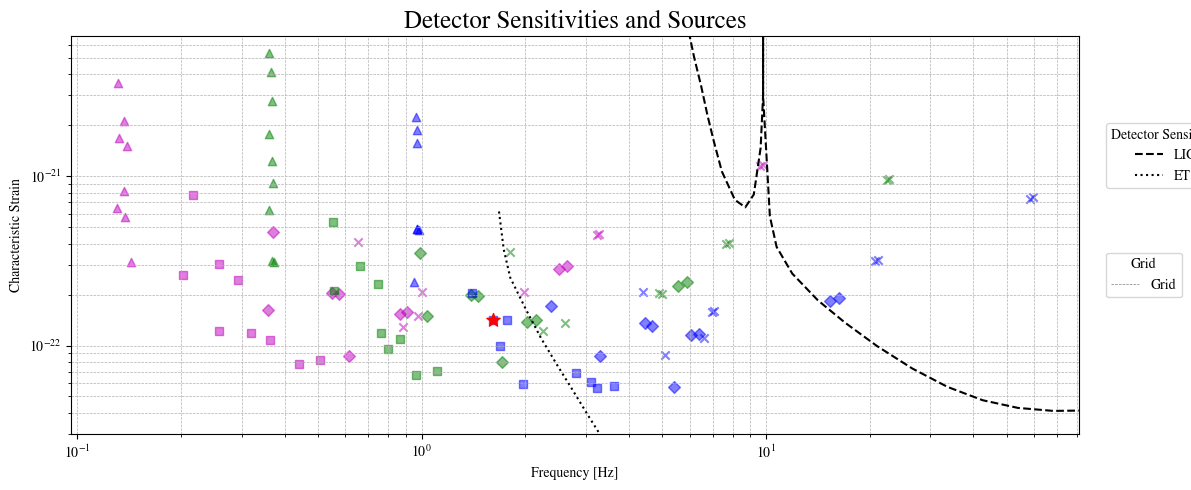

In [157]:
fig, ax = plt.subplots(figsize=(12, 5))

for i in range(3):
    for j in range(4):
        plt.scatter(fs_max[i,j].flatten(),hcs_max[i,j].flatten(),c=cs[i],marker=ss[j],alpha=0.5)

plt.scatter([1.606981595370176], [1.41270422908376e-22],c="r",marker="*",s=100)
plt.xscale("log")
plt.yscale("log")

plt.loglog(LIGO_full[::2],LIGO_full[1::2],c="k",linestyle="--",label="LIGO")
plt.loglog(ET2[::2],ET2[1::2],c="k",linestyle=":",label="ET")

plt.xlim(lims_all_pts_x)
plt.ylim(3e-23,lims_all_pts_y[1])

# ---- Styling ----
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Characteristic Strain')
ax.set_title('Detector Sensitivities and Sources', fontsize=18)

# Enable grid and set style
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# ---- PROXY ARTISTS FOR LEGENDS ----

# Sensitivity curves
ligo_proxy = mlines.Line2D([], [], color='black', linestyle='--', label='LIGO')
et_proxy   = mlines.Line2D([], [], color='black', linestyle=':',  label='ET')

# Grid proxy: must match your grid style
grid_proxy = mlines.Line2D([], [], color='gray', linestyle='--', linewidth=0.5, label='Grid')

# ---- CREATE SEPARATE LEGENDS ----

# Detector sensitivities legend (placed outside)
leg1 = ax.legend(handles=[ligo_proxy, et_proxy],
                 title="Detector Sensitivities",
                 loc="center left",
                 bbox_to_anchor=(1.02, 0.7),
                 frameon=True)

ax.add_artist(leg1)

# Grid legend (placed below or elsewhere)
leg2 = ax.legend(handles=[grid_proxy],
                 title="Grid",
                 loc="center left",
                 bbox_to_anchor=(1.02, 0.4),
                 frameon=True)

# Or if you want the grid legend inside:
# leg2 = ax.legend(handles=[grid_proxy], loc="lower right")

plt.tight_layout()
plt.show()

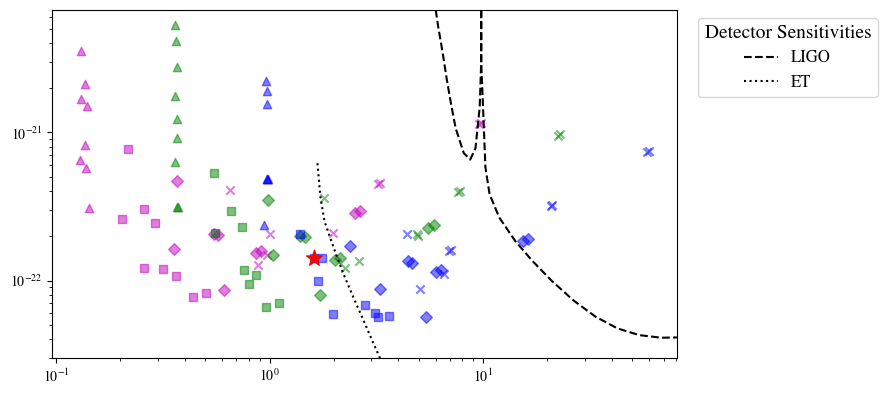

In [156]:
cs = ["m","g","b"]                 # WD masses → colors
ss = ["^","s","D","x"]             # BH masses → markers

WD_labels = ["0.2 M$_\odot$", "0.6 M$_\odot$", "1.0 M$_\odot$"]
BH_labels = ["5 M$_\odot$", "10 M$_\odot$", "20 M$_\odot$", "30 M$_\odot$"]

fig, ax = plt.subplots(figsize=(10,6))

# -------------------------------------------------------------------
# 1) PLOT YOUR DATA
# -------------------------------------------------------------------

for i in range(3):
    for j in range(4):
        ax.scatter(fs_max[i,j].flatten(),
                   hcs_max[i,j].flatten(),
                   c=cs[i], marker=ss[j],
                   alpha=0.5)

ax.scatter([1.606981595370176],
           [1.41270422908376e-22],
           c="r", marker="*", s=140)

# Sensitivity curves
ax.loglog(LIGO_full[::2],   LIGO_full[1::2],   c="k", ls="--", label="LIGO")
ax.loglog(ET2[::2],         ET2[1::2],         c="k", ls=":",  label="ET")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lims_all_pts_x)
ax.set_ylim(3e-23, lims_all_pts_y[1])

# -------------------------------------------------------------------
# 2) BUILD A GRID-STYLE LEGEND FOR (WD mass) × (BH mass)
# -------------------------------------------------------------------
# The grid has 4 columns (BH masses) and 3 rows (WD masses)

grid_handles = []
grid_labels  = []

for i in range(3):          # each WD mass
    for j in range(4):      # each BH mass
        h = mlines.Line2D([], [], color=cs[i], marker=ss[j],
                          linestyle='', markersize=10)
        grid_handles.append(h)
        grid_labels.append(f"{WD_labels[i]}, {BH_labels[j]}")

# Now place the grid legend outside the plot
grid_leg = ax.legend(
    handles=grid_handles,
    labels=grid_labels,
    title="WD Mass × BH Mass",
    title_fontsize=14,
    fontsize=12,
    ncol=4,                 # four BH-mass columns
    bbox_to_anchor=(0.5, -0.25),
    loc="upper center"
)
ax.add_artist(grid_leg)

# -------------------------------------------------------------------
# 3) SECOND LEGEND (sensitivity curves only)
# -------------------------------------------------------------------

sens_leg = ax.legend(
    title="Detector Sensitivities",
    title_fontsize=14,
    fontsize=12,
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

# -------------------------------------------------------------------
# 4) Ensure nothing is cut off
# -------------------------------------------------------------------

plt.subplots_adjust(bottom=0.30, right=0.75)
plt.show()

In [144]:
import matplotlib.lines as mlines

In [126]:
print(LIGO)

[5.03197811e+00 4.47251304e-20 5.16011003e+00 3.37369335e-20
 5.36272680e+00 2.19708054e-20 5.57532569e+00 1.49174615e-20
 5.76740659e+00 1.00983496e-20 5.93805200e+00 7.43058539e-21
 6.17613731e+00 5.07526725e-21 6.47382119e+00 3.42547596e-21
 6.75687575e+00 2.29140852e-21 7.05230630e+00 1.60282522e-21
 7.43982480e+00 1.06687118e-21 8.11644348e+00 7.25810494e-22
 8.69992542e+00 6.55285050e-22 9.21051566e+00 7.80328347e-22
 9.64048043e+00 1.47260105e-21]


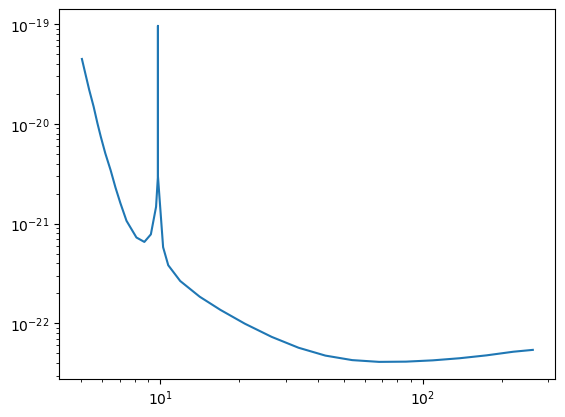

In [12]:
LIGO2=np.array([10.255384766672897, 5.800823516270504e-22,
10.726707893156275, 3.825844118027608e-22,
11.912427653544876, 2.659269126447393e-22,
14.136477615336082, 1.849782555628661e-22,
16.956196932948057, 1.364266888952066e-22,
21.001708152857145, 9.923569993354146e-23,
26.575007940026875, 7.31781236819967e-23,
33.62731459138053, 5.696554177677685e-23,
42.551117545462176, 4.751471978971895e-23,
53.84306259268901, 4.2811134331473614e-23,
68.13159222581649, 4.110725838282178e-23,
86.21192101088306, 4.133046350806229e-23,
109.09029249973132, 4.257993284498907e-23,
138.0399807606037, 4.470651728993636e-23,
174.67215323888414, 4.7772716294439583e-23,
221.02553875330452, 5.195558767541385e-23,
262.291001622486, 5.422645191029394e-23
               ])

gap=np.array([9.8,3e-21,9.8,9.6e-20,9.8,3e-21])
LIGO_inter=np.append(LIGO,gap)
LIGO_full=np.append(LIGO_inter,LIGO2)
plt.loglog(LIGO_full[::2],LIGO_full[1::2])

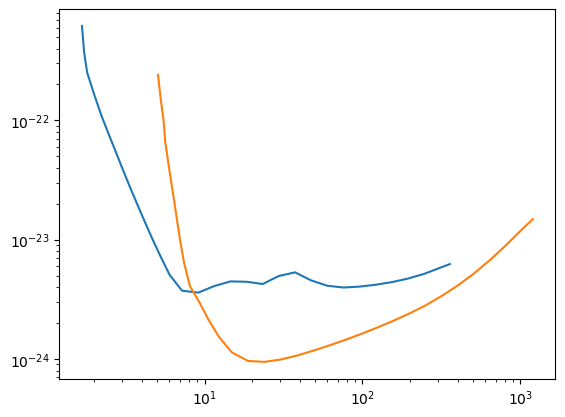

In [9]:
ET2=np.array([1.6765167673567882, 6.192813665900481e-22,
1.7302784634279216, 3.697201557357763e-22,
1.8082926816552696, 2.5129895885553833e-22,
2.0037630966512494, 1.6455440712535113e-22,
2.2209043967999675, 1.1049698606911143e-22,
2.471684006892143, 7.683288424958827e-23,
2.7507810956333767, 5.406518823924328e-23,
3.0613932100520946, 3.7818244297996107e-23,
3.407078957111686, 2.677064808591656e-23,
3.7917987737993566, 1.9177424680400494e-23,
4.219960300883333, 1.3820018539685775e-23,
4.696468880174194, 1.0018758423646537e-23,
5.283002800326453, 7.198446398580689e-24,
6.006708287517489, 5.085503811523304e-24,
7.204830751574483, 3.738311226648316e-24,
9.116802930317535, 3.5992591231956495e-24,
11.536162130121179, 4.087704979713212e-24,
14.59755549282305, 4.469754118399944e-24,
18.47136196271628, 4.439600886955364e-24,
23.373174565113413, 4.2513790263943975e-24,
29.575799031709632, 4.967558740289179e-24,
37.424436544862296, 5.322650978840326e-24,
47.355895582019166, 4.555277132956878e-24,
59.92290207727863, 4.109900493056497e-24,
75.824860859067, 3.973130120358044e-24,
95.94678036257714, 4.043672906226055e-24,
121.4085269349208, 4.19421238406213e-24,
153.62714993463706, 4.409651071032638e-24,
194.39574626986928, 4.724862818272347e-24,
245.9832535062818, 5.173461643914327e-24,
311.2607254355054, 5.828006387081148e-24,
357.70608984613557, 6.248833706029565e-24])

CE2=np.array([5.0756559454308645, 2.4057917575366554e-22,
5.2923949104842904, 1.481067406940386e-22,
5.513991271867219, 9.820158398152568e-23,
5.633245663354221, 6.719562579949691e-23,
5.879547786364889, 4.539773311357005e-23,
6.176137311410087, 2.953543578443198e-23,
6.473821188207264, 1.9890023158130332e-23,
6.756875753538901, 1.3555048412040004e-23,
7.052306299705602, 9.341516137361423e-24,
7.439824797544276, 6.326862908495054e-24,
8.092252339962311, 4.070349770554085e-24,
9.2148628447929, 3.0367011451780574e-24,
10.58987622697132, 2.1409762589676267e-24,
12.300965520449918, 1.542873043959833e-24,
14.913265567733063, 1.1342261592419963e-24,
18.87085317011784, 9.628504315372243e-25,
23.878680209292217, 9.460532885956494e-25,
30.215452549890486, 9.892763897895247e-25,
38.233837246976606, 1.0657476536895486e-24,
48.38008989653851, 1.170098160339721e-24,
61.21889056747099, 1.2951433868888535e-24,
77.46477053528827, 1.4432883692621778e-24,
98.02187884262997, 1.621496501056284e-24,
124.03430185676822, 1.834081471837947e-24,
156.9497363113713, 2.0914566907011208e-24,
198.6000594952735, 2.4109191905561392e-24,
251.30328064570654, 2.8170583292676567e-24,
317.9925475540856, 3.381955119188928e-24,
402.3793881246516, 4.143419938121835e-24,
509.1602719401176, 5.222720910074265e-24,
644.277987822339, 6.79136892522095e-24,
815.2523841082851, 9.061262286458594e-24,
1031.5988786776852, 1.2337841630112133e-23,
1198.2823940122873, 1.4858776610263713e-23])
plt.loglog(ET2[::2],ET2[1::2])
plt.loglog(CE2[::2],CE2[1::2])

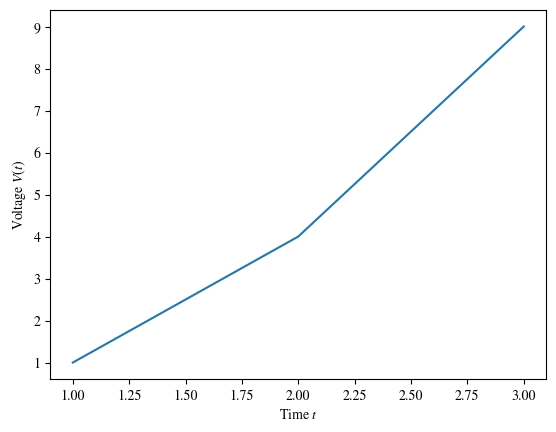

In [48]:
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})

plt.plot([1,2,3], [1,4,9])
plt.xlabel(r"Time $t$")
plt.ylabel(r"Voltage $V(t)$")
plt.show()

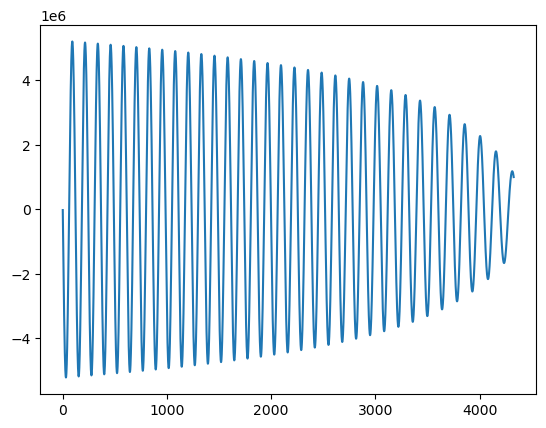

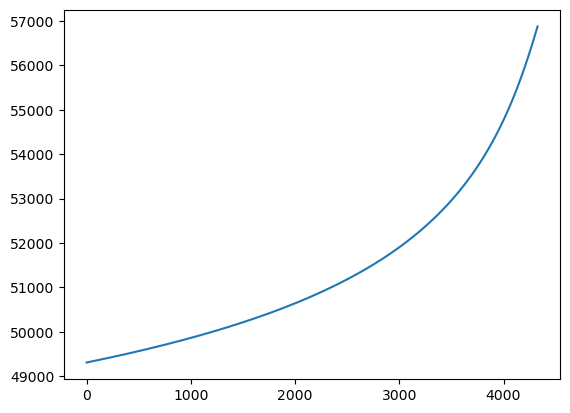

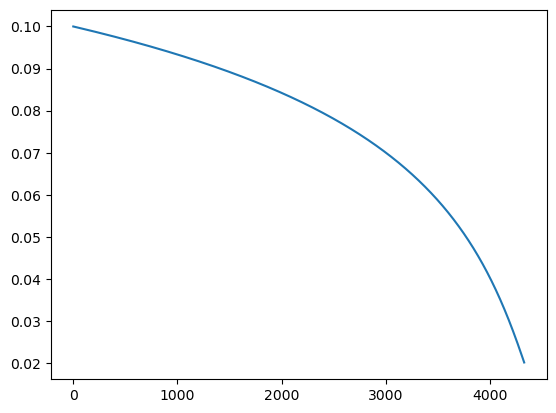

In [10]:
df = pd.read_csv('20251202_M_WD=0.1_M_NS=0.5_A=10.0_6.csv')

mask = np.ones(len(df['t']), dtype=bool)
mask[499::500] = False 

plt.plot(df['t'][mask],df['ddI_xx'][mask])
plt.show()
plt.plot(df['t'][mask],df['a'][mask])
plt.show()
plt.plot(df['t'][mask],df['M_WD'][mask])
plt.show()

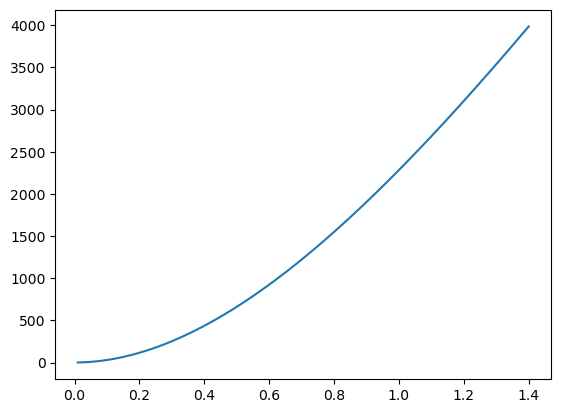

In [6]:
plt.plot(df['M_WD'],df['a'])

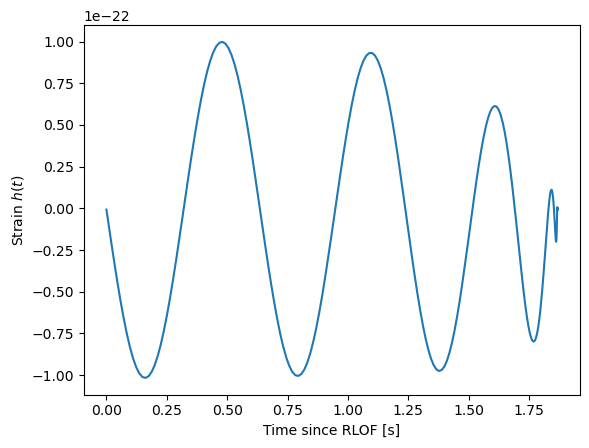

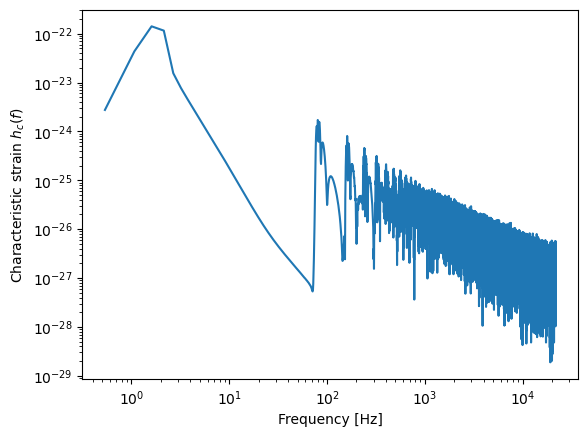

(1.606981595370176, 1.41270422908376e-22)

In [2]:
def calc_hc(filename,plot=False,return_hc=False):

    #reading in the data as a csv
    df = pd.read_csv(filename)
    t=df["t"]
    h_p=df["ddI_xx"]*1.065e-30
    
    #linearly interpolate data for purposes of FFT
    dt_min=max(min(np.array(t[1:])-np.array(t[:-1])), (t[1]-t[0])/10)#minimal time step from integration
    #print(dt_min)
    #yeep
    f_interp = interp1d(np.array(t),np.array(h_p), kind='linear', bounds_error=False, fill_value="extrapolate")
    t_evenly_spaced=np.linspace(0,max(t),num=int(2*max(t)/dt_min) + 1)
    h_evenly_spaced=f_interp(t_evenly_spaced)

    t=t_evenly_spaced

    #                   # shape (N,)
    h = h_evenly_spaced * signal.windows.hann(len(h_evenly_spaced)) #windowing h
    dt = t_evenly_spaced[1] - t_evenly_spaced[0]                       # sampling interval

    N = len(t_evenly_spaced)
    
    # take fourier transform
    h_f = np.fft.rfft(h) * dt              # multiply by dt to approximate integral
    freqs = np.fft.rfftfreq(N, dt)
    
    #Magnitude of fourier transform 
    h_tilde = np.abs(h_f)  
    
    # characteristic strain
    h_char = 2 * freqs * h_tilde
    
    # Remove f = 0 as unphysical
    mask = freqs > 0
    freqs = freqs[mask]
    h_char = h_char[mask]

    if plot:
        #gravitational waveform
        plt.plot(df["t"],h_p)
        plt.xlabel("Time since RLOF [s]")
        plt.ylabel("Strain $h(t)$")
        plt.show()

        #Characteristic strain
        plt.loglog(freqs, h_char)
        plt.xlabel("Frequency [Hz]")
        plt.ylabel("Characteristic strain $h_c(f)$")
        #plt.grid(True, which="both", ls=":")
        plt.show()

    if return_hc:
        return(freqs, h_char)
    return(freqs[h_char==max(h_char)][0], max(h_char))

calc_hc('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv', plot=True)

In [54]:
df = pd.read_csv('20251202_M_WD=0.1_M_NS=0.5_A=10.0_6.csv')
t=df["t"]
h_p=df["ddI_xx"]*Mpc_conversion
h_c=df["ddI_xy"]*Mpc_conversion
print(df.head()) # Prints the first 5 rows of the DataFrame

mask = np.ones(len(t), dtype=bool)
mask[499::500] = False 

t=t[mask]
h_p=h_p[mask]
h_c=h_c[mask]

          t         ddI_xx        ddI_xy             a      M_WD  M_NS  \
0  0.086565  -29234.114823  5.221427e+06  49309.836152  0.099999   0.5   
1  0.330613  -94904.822777  5.220621e+06  49309.953715  0.099998   0.5   
2  0.605796 -168933.545799  5.218722e+06  49310.086277  0.099996   0.5   
3  0.898538 -247646.385539  5.215549e+06  49310.227299  0.099995   0.5   
4  1.203716 -329640.500195  5.210978e+06  49310.374313  0.099993   0.5   

           R_WD             J     theta  
0  18684.492940  1.808785e+06  0.002231  
1  18684.493823  1.808784e+06  0.008520  
2  18684.496045  1.808783e+06  0.015611  
3  18684.499819  1.808782e+06  0.023155  
4  18684.505280  1.808781e+06  0.031019  


In [ ]:
t_clean=np.zeros(6500-)

for i in range()

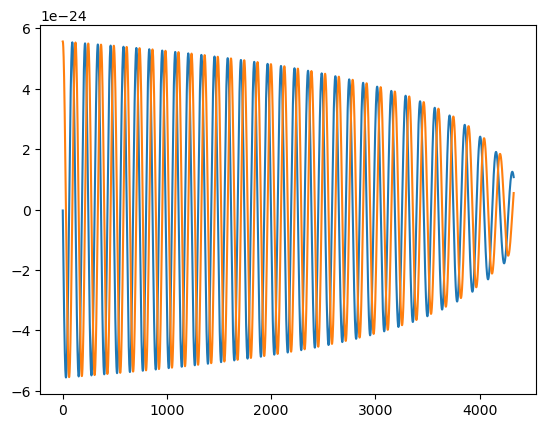

In [25]:
plt.plot(t[:-1],h_p[:-1])
plt.plot(t[:-1],h_c[:-1])

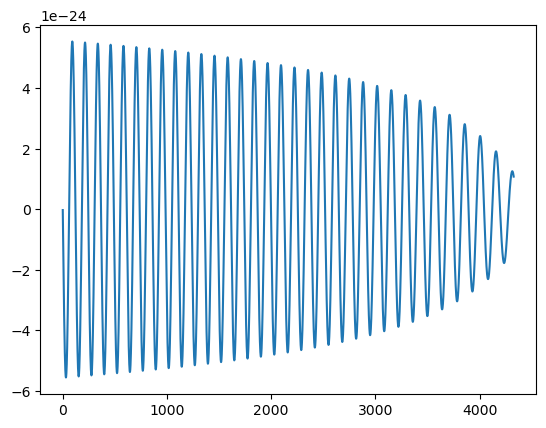

In [28]:
plt.plot(t[:-1],h_p[:-1])


In [57]:
dt_min=min(np.array(t[1:])-np.array(t[:-1]))
dt_min

0.24404754806259948

In [58]:
f_interp = interp1d(np.array(t),np.array(h_p), kind='linear', bounds_error=False, fill_value="extrapolate")

t_evenly_spaced=np.linspace(0,max(t),num=int(2*max(t)/dt_min) + 1)

h_evenly_spaced=f_interp(t_evenly_spaced)

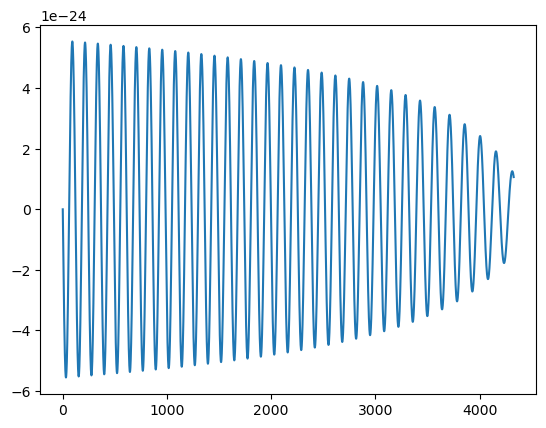

In [39]:
plt.plot(t_evenly_spaced,h_evenly_spaced)

In [70]:
t_evenly_spaced

array([0.00000000e+00, 1.22027104e-01, 2.44054207e-01, ...,
       4.32647096e+03, 4.32659299e+03, 4.32671501e+03])

In [46]:
window_function = signal.windows.hann(len(h_evenly_spaced))
h_windowed = h_evenly_spaced * window_function

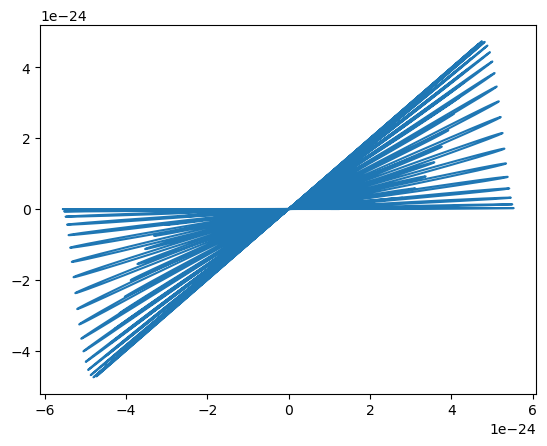

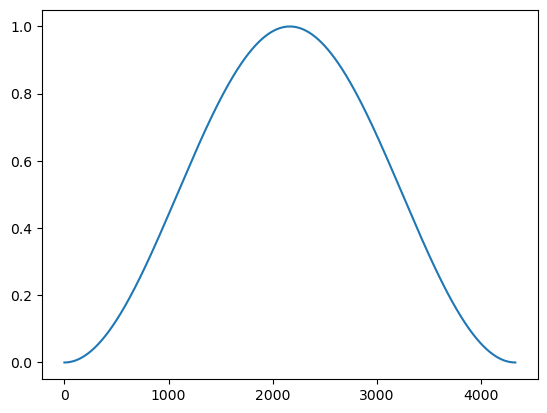

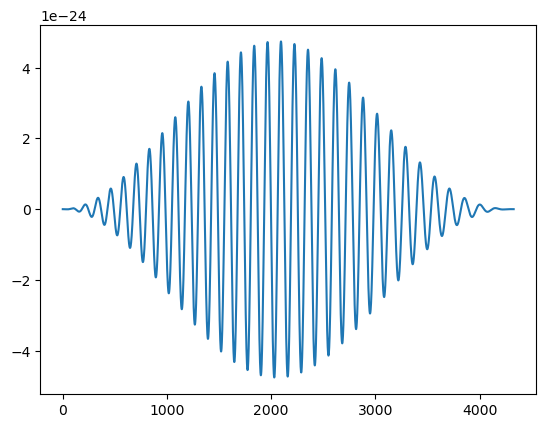

In [47]:
plt.plot(h_evenly_spaced,h_windowed)
plt.show()

plt.plot(t_evenly_spaced,window_function)
plt.show()

plt.plot(t_evenly_spaced,h_windowed)

In [66]:
negative=(h_evenly_spaced<0)

new_period=[]

for i in range(len(negative)-1):
    if negative[i] and not negative[i+1]:
        new_period.append(t_evenly_spaced[i])

new_period=np.array(new_period)
print(new_period[1:]-new_period[:-1])
        

[122.27115787 122.51521207 122.75926628 123.2473747  123.4914289
 123.85751021 124.22359152 124.58967284 124.95575415 125.44386256
 125.93197098 126.42007939 126.90818781 127.39629622 128.00643174
 128.49454015 129.22670277 129.9588654  130.56900092 131.54521774
 132.27738037 133.3756243  134.35184113 135.45008506 136.91441031
 138.37873555 140.087115   142.28360287 144.72414494 147.65279543
 151.67968985 156.92685531]


In [67]:
1/(122.27115787)

0.008178543635476248

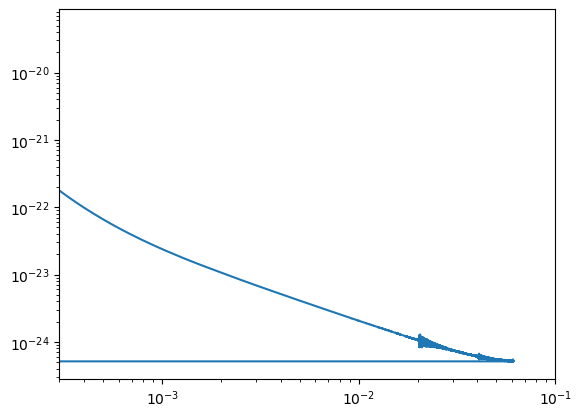

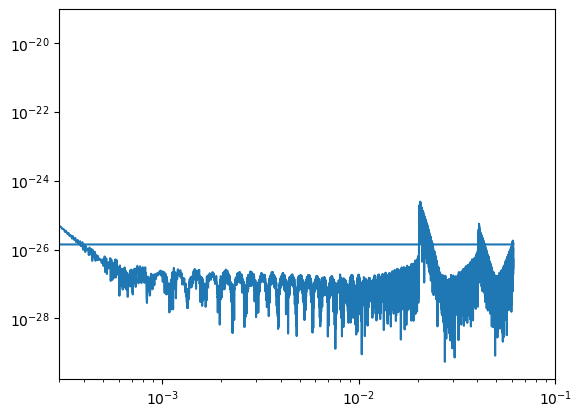

In [56]:
fft_output = np.abs(np.fft.rfft(h_evenly_spaced))
fft_output_windowed = np.abs(np.fft.rfft(h_windowed))
frequencies = np.fft.fftfreq(len(t_evenly_spaced), 1 / (t_evenly_spaced[1]-t_evenly_spaced[0]))[:17730]

plt.plot(frequencies,fft_output)
plt.xlim(3e-4,1e-1)
plt.xscale("log")
plt.yscale("log")
plt.show()

plt.plot(frequencies,fft_output_windowed)
plt.xlim(3e-4,1e-1)
plt.xscale("log")
plt.yscale("log")
plt.show()


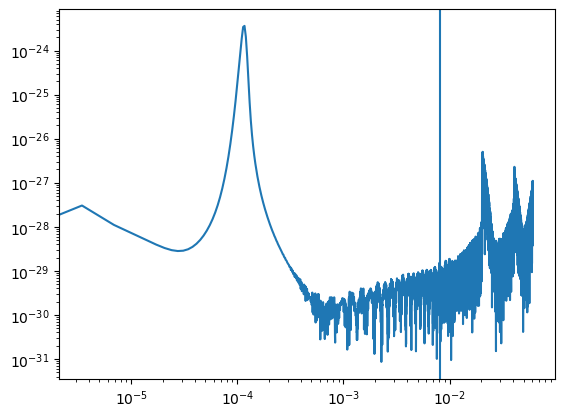

In [69]:
plt.axvline(1/(122.27115787))

plt.plot(frequencies[:-1],(fft_output_windowed*frequencies)[:-1])
plt.xscale("log")
plt.yscale("log")
plt.show()

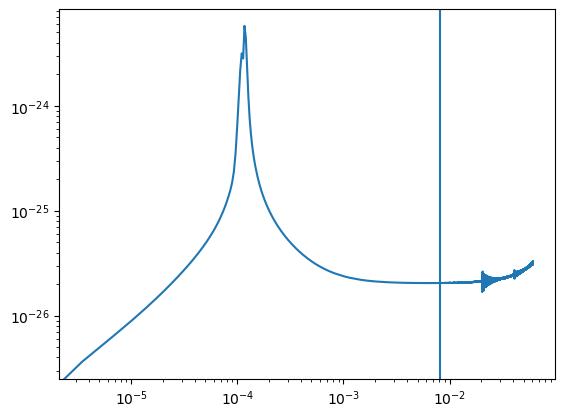

In [68]:
plt.axvline(1/(122.27115787))

plt.plot(frequencies[:-1],(fft_output*frequencies)[:-1])

plt.xscale("log")
plt.yscale("log")
plt.show()

In [55]:
fft_output_windowed

array([ 9.92052787e-20+0.00000000e+00j, -4.93317374e-21-1.07478526e-20j,
       -1.91988967e-21-6.57227616e-21j, ...,
       -5.20845930e-25-6.16465665e-26j, -5.22529849e-25-3.30963696e-26j,
       -6.09006807e-25+0.00000000e+00j])

In [53]:
1 / (t_evenly_spaced[1]-t_evenly_spaced[0])

8.194900722990358

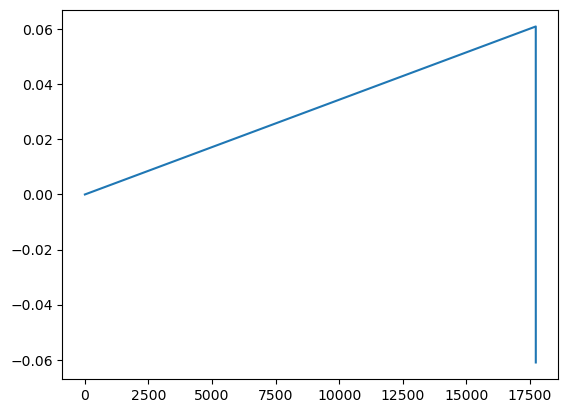

In [52]:
plt.plot(frequencies)

In [42]:
1 / (t_evenly_spaced[1]-t_evenly_spaced[0])

8.194900722990358

In [31]:
t[2:]-t[:-2]

0       NaN
1       NaN
2       0.0
3       0.0
4       0.0
       ... 
6494    0.0
6495    0.0
6496    0.0
6497    NaN
6498    NaN
Name: t, Length: 6487, dtype: float64

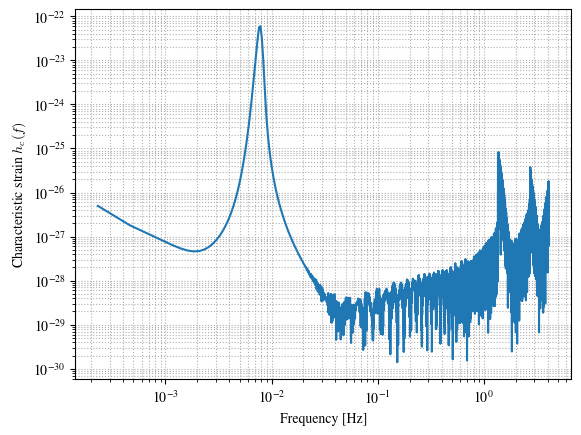

In [59]:
t = t_evenly_spaced                    # shape (N,)
h = h_evenly_spaced                    # shape (N,)
h = h_evenly_spaced * signal.windows.hann(len(h_evenly_spaced))
dt = t[1] - t[0]                       # sampling interval

N = len(t)

# --- FFT ---
# Use rfft since the data are real → returns positive frequencies only
h_f = np.fft.rfft(h) * dt              # multiply by dt to approximate integral
freqs = np.fft.rfftfreq(N, dt)

# --- Convert to one-sided characteristic strain ---
# magnitude of Fourier transform
h_tilde = np.abs(h_f)  

# characteristic strain
h_char = 2 * freqs * h_tilde

# Remove f = 0 (DC), which is unphysical for GW strain
mask = freqs > 0
freqs = freqs[mask]
h_char = h_char[mask]

plt.loglog(freqs, h_char)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Characteristic strain $h_c(f)$")
plt.grid(True, which="both", ls=":")
plt.show()

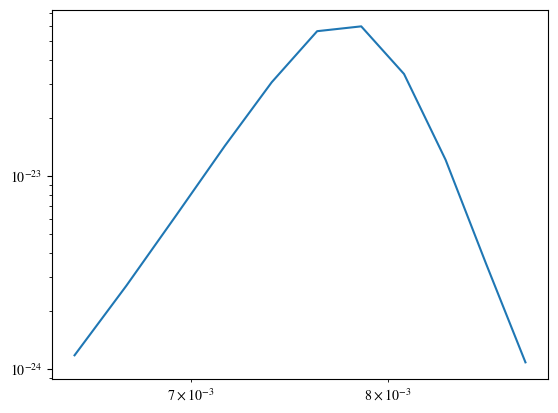

In [63]:
plt.loglog(freqs[h_char>max(h_char)/100], h_char[h_char>max(h_char)/100])

4.573525138713e-05


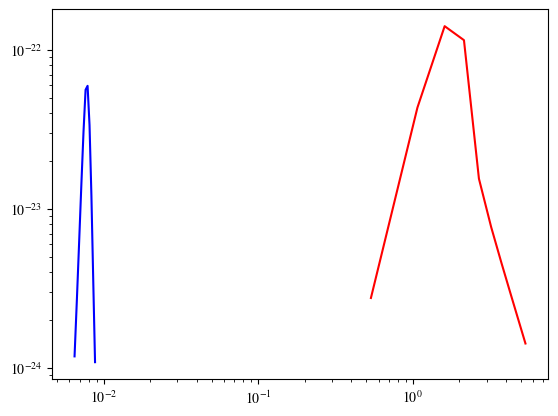

In [80]:
freq_high,hc_high=calc_hc('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv', return_hc=True)

plt.loglog(freqs[h_char>max(h_char)/100], h_char[h_char>max(h_char)/100],c="b")
plt.loglog(freq_high[np.logical_and(hc_high>max(hc_high)/100,freq_high<10)], 
           hc_high[np.logical_and(hc_high>max(hc_high)/100,freq_high<10)],c="r")

x_limit_hc=plt.xlim()

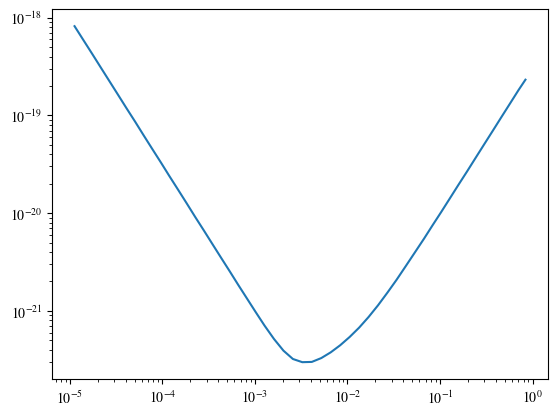

In [67]:
LISA=np.array([

    0.000011213426370482527, 8.1724692094540625e-19,
0.000014038180146887472, 5.851261630281622e-19,
0.000017387493410699886, 4.260837790824695e-19,
0.000021535905932519583, 3.088874619526138e-19,
0.000026674071608787655, 2.2426024601180655e-19,
0.000033038131686689125, 1.6281870951754896e-19,
0.00004092056740926707, 1.1803466926052994e-19,
0.00005068364194973562, 8.607991033176446e-20,
0.00006277604940314833, 6.221765171639906e-20,
0.00007775353599440894, 4.517161619961431e-20,
0.00009630444121784245, 3.2893577750800746e-20,
0.00011928133273511499, 2.377513122769146e-20,
0.00014774018891694921, 1.7312843625467562e-20,
0.00018298892979077267, 1.2569569985352416e-20,
0.00022664752679310294, 9.085152674525671e-21,
0.00028072245386737507, 6.6255883332666926e-21,
0.0003476989015514742, 4.803189571338967e-21,
0.0004306549920556687, 3.48723922978479e-21,
0.0005334032444592317, 2.539377254815778e-21,
0.0006606657915226434, 1.8381704054392154e-21,
0.0008182914007783083, 1.340534477420879e-21,
0.0010135242738154942, 9.776202901736324e-22,
0.001268839324304848, 7.066136394714952e-22,
0.0016055558372966138, 5.154562653315601e-22,
0.002031628037765546, 3.915974469774127e-22,
0.002570768569958217, 3.2180178137161435e-22,
0.003247187606650938, 2.9851109729087435e-22,
0.00411623867994079, 3.0038689114604174e-22,
0.005208579931037187, 3.2884822024598553e-22,
0.006590799758578039, 3.765213179334244e-22,
0.008339824296220901, 4.447400921307635e-22,
0.010552993845900444, 5.404677056650562e-22,
0.013353480260018995, 6.730016816322813e-22,
0.01689714195408043, 8.645401897460015e-22,
0.021381198058995004, 1.1395282569038047e-21,
0.02705520446477476, 1.539033042391551e-21,
0.03387063165520557, 2.0738211052787245e-21,
0.042402920673405606, 2.845594690730519e-21,
0.05365553817691622, 3.975524238574276e-21,
0.06717180689646209, 5.475734615575452e-21,
0.0831980596898093, 7.519637551731374e-21,
0.10304795204956252, 1.0265130740407889e-20,
0.1276337508494753, 1.4117758100325415e-20,
0.15808537706863784, 1.9445258558402393e-20,
0.19580233501408567, 2.662408976869043e-20,
0.24251803112897866, 3.6725649890621744e-20,
0.3003794383680126, 5.058450164492062e-20,
0.37204576737758666, 6.956947513949847e-20,
0.4608106792382831, 9.596512816945805e-20,
0.5707536564568358, 1.3198199806944787e-19,
0.7069274889577815, 1.8178694232307488e-19,
0.8389108344631622, 2.317290388196878e-19,
])

plt.loglog(LISA[::2],LISA[1::2])

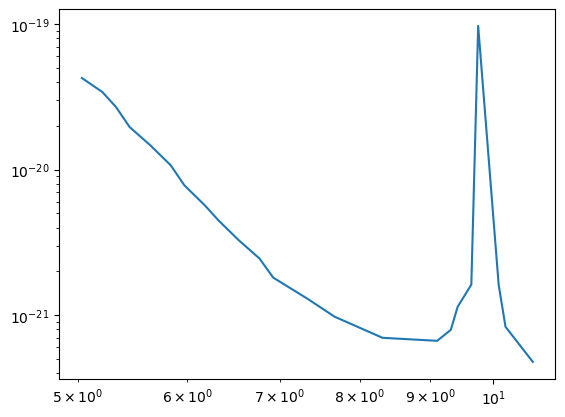

In [8]:
"""LIGO=np.array([
 5.116134058561447, 3.95841942296654e-20,
5.171162962011658, 3.3065468841208555e-20,
5.226783753825304, 2.7688884039253395e-20,
5.378048174565751, 2.1764564932404473e-20,
5.45531416276158, 1.771270978344158e-20,
5.633245663354221, 1.3480840082125517e-20,
5.81698060953376, 9.934278228196092e-21,
5.879547786364889, 8.246970987769012e-21,
6.045390040506615, 6.345548074117576e-21,
6.229224594123068, 4.926338155665972e-21,
6.4049300540974246, 3.69943632075665e-21,
6.5855915737222475, 2.764337784405858e-21,
6.7931168851599, 2.2491495716036238e-21,
6.932614851327136, 1.7895529085980318e-21,
7.1129247347296305, 1.448465644123337e-21,
7.360653941108641, 1.184086473482107e-21,
7.600730344045156, 9.423612388516561e-22,
8.087306701777345, 7.366998664163811e-22,
8.73488785820693, 6.674066272337696e-22,
    9.31397748721406, 7.669241809695944e-22,
9.31397748721406, 9.284319262547484e-22,

9.826997937753035, 9.553045450042773e-20,
10.323352946499847, 9.21592659843033e-22 ,   
10.255384766672897, 5.931857028927911e-22,
10.365691215196433, 4.9673120378296495e-22,
10.703780450311347, 3.933685674908951e-22,
11.291944484178176, 3.0387778516483905e-22,
12.040557179413645, 2.513900313529763e-22,
13.257552624485397, 2.0915887731852787e-22,
14.59755549282305, 1.7428149904674755e-22,
16.24587915775151, 1.461963662296548e-22,
18.27479906158412, 1.2130512441674396e-22,
20.778218586056976, 1.0045218872770164e-22,
23.62457535949177, 8.48521383018391e-23,
26.86084750743874, 7.203141746914163e-23,
30.54044857267646, 6.237409565992754e-23,
34.72410908710129, 5.523159500181833e-23,
39.48087890796954, 5.001173606962482e-23,
44.88926686170237, 4.585067491822381e-23,
51.03853650467687, 4.3522117206077244e-23,
58.0301793870831, 4.193162022378237e-23,
65.97959013555337, 4.110725838282178e-23,
75.01797100121652, 4.1005359280110634e-23,
85.29449730708251, 4.1209410706753986e-23,
96.97877953470545, 4.172399272362189e-23,
110.26366268601083, 4.2772513754560443e-23,
125.36840912277526, 4.3738692557747114e-23,
142.54231741541457, 4.506096553872946e-23,
162.0688369289169, 4.653857498462016e-23,
184.27024605572612, 4.8664820472298094e-23,
209.51297130817738, 5.0888209455998065e-23,
238.21363506024971, 5.347798036034582e-23,
270.84593175450334, 5.64792092211551e-23,
307.9484460635987, 6.054378464865008e-23,
350.1335420424249, 6.506215068908129e-23,
398.0974699831934, 7.079078391041848e-23,
452.63185778361486, 7.759946052690374e-23,
513.8508269587167, 9.40412277787021e-23,
501.94881346352724, 8.443198670109341e-23,
585.135595651734, 9.702171001321441e-23,
665.2918736869808, 1.103873418990959e-22,
756.4285620001352, 1.2621919599439849e-22,
860.0498398373711, 1.4721588496845227e-22,
977.8659402395166, 1.72559836784704e-22,
1111.8213768417515, 2.022668768220562e-22,
1264.1270373927825, 2.406451781813714e-22,
1437.296673685834, 2.8488775107936874e-22,
1634.1883901550334, 3.406292631794566e-22,
1858.051815892003, 4.0727723285601853e-22,
2112.5817386403346, 4.942716027100098e-22,
2376.4184381737996, 5.857245522498903e-22,
2673.2052492923026, 6.961689799676395e-22,
3007.057254754925, 8.274388478467108e-22,
3346.607505976391, 9.689241881008395e-22,
3764.5595609719094, 1.1550598986817639e-21,
4234.708929205693, 1.3687756655809969e-21,
4763.574443344598, 1.6188169081041706e-21,
])"""
LIGO=np.array([
    5.031978105043031, 4.2644795512308426e-20,
5.2071464457848915, 3.414548873833615e-20,
5.3273000474380074, 2.6909488168583843e-20,
5.450226163392528, 1.9588517821186576e-20,
5.6399541498383625, 1.471933199271179e-20,
5.836286762911016, 1.0714804207677656e-20,
5.970957620000472, 7.79974453091444e-21,
6.178812804800929, 5.677753281197419e-21,
6.3213873646230985, 4.47454233018437e-21,
6.541441369774271, 3.257202501487896e-21,
6.7691556814989475, 2.447548376275641e-21,
6.925352255524906, 1.810183559576131e-21,
7.331794500935581, 1.2969509806190185e-21,
7.674056919594393, 9.745633761711562e-22,
8.311909338520294, 6.9825014138154e-22,
9.106054852354657, 6.657718877657661e-22,
9.316174790165762, 7.9281631156407005e-22,
9.423046000943504, 1.1422522372119138e-21,
9.64048043021197, 1.6197808671541954e-21,
9.751071937913549, 9.736796104204231e-20,
10.090516795614143, 1.6197808671541954e-21,
10.206270929860224, 8.314921549135258e-22,
10.682719495555114, 4.770088083821632e-22,
])
plt.loglog(LIGO[::2],LIGO[1::2])

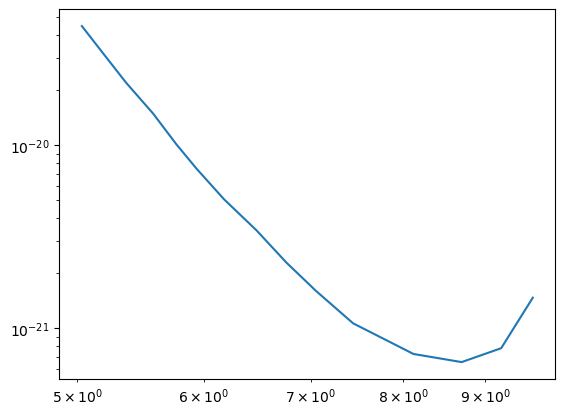

In [11]:
LIGO=np.array([5.031978105043031, 4.472513039801422e-20,
              5.160110032777985, 3.373693349874641e-20,
5.362726798323402, 2.1970805393587665e-20,
5.575325687133135, 1.4917461460893983e-20,
5.767406591212829, 1.0098349608922226e-20,
5.938052001996863, 7.430585392224896e-21,
6.176137311410087, 5.075267249278436e-21,
6.473821188207264, 3.425475958700577e-21,
6.756875753538901, 2.2914085160450556e-21,
7.052306299705602, 1.602825216530006e-21,
7.439824797544276, 1.0668711780405344e-21,
8.116443475955927, 7.258104937359866e-22,
8.69992542291971, 6.552850502852725e-22,
9.210515656214554, 7.803283468962285e-22,
9.64048043021197, 1.472601051965871e-21])
plt.loglog(LIGO[::2],LIGO[1::2])

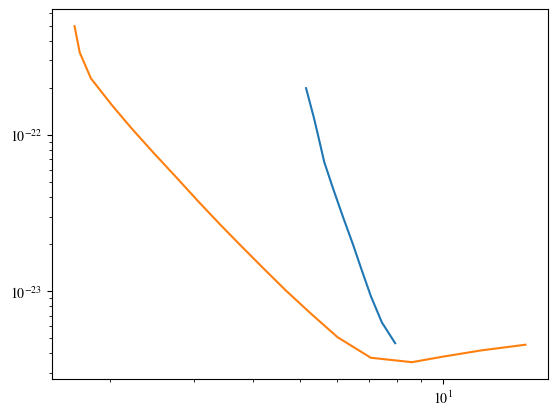

In [79]:
ET=np.array([
    1.6876198152881527, 4.9673120378296495e-22,
1.7302784634279216, 3.3726431307877807e-22,
1.82628602890191, 2.302942467744527e-22,
2.017033395009371, 1.5644547724122134e-22,
2.2209043967999675, 1.1049698606911143e-22,
2.471684006892143, 7.683288424958827e-23,
2.7507810956333767, 5.406518823924328e-23,
3.0613932100520946, 3.7818244297996107e-23,
3.407078957111686, 2.677064808591656e-23,
3.7917987737993566, 1.9177424680400494e-23,
4.219960300883333, 1.3820018539685775e-23,
4.696468880174194, 1.0018758423646537e-23,
5.283002800326453, 7.198446398580689e-24,
6.006708287517489, 5.085503811523304e-24,
7.052306299705602, 3.756913861826407e-24,
8.603981126153856, 3.5197122943859735e-24,
10.014606466795195, 3.8231349580819844e-24,
12.04763774820519, 4.191045412417426e-24,
14.881159517759741, 4.552341466283808e-24])

CE=np.array([
    5.160110032777985, 1.9927711192182594e-22,
5.362726798323402, 1.278587471284057e-22,
5.513991271867219, 8.917038021474831e-23,
5.633245663354221, 6.719562579949691e-23,
5.879547786364889, 4.539773311357005e-23,
6.176137311410087, 2.953543578443198e-23,
6.473821188207264, 1.9890023158130332e-23,
6.756875753538901, 1.3555048412040004e-23,
7.052306299705602, 9.341516137361423e-24,
7.439824797544276, 6.326862908495054e-24,
7.933056702959072, 4.656599001737157e-24
])
plt.loglog(CE[::2],CE[1::2])
plt.loglog(ET[::2],ET[1::2])
plt

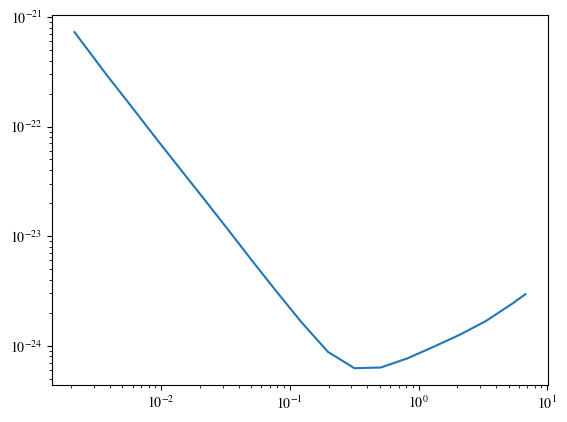

In [104]:
DECIGO=np.array([0.002128543668649185, 7.267163912882625e-22,
0.0037859732054767595, 2.950512489365808e-22,
0.005932828904520381, 1.50443896540326e-22,
0.009297070237949531, 7.602713800382267e-23,
0.014260694358823706, 4.01770408402398e-23,
0.0218743537900428, 2.129519395751316e-23,
0.0335528791019842, 1.1220095551013698e-23,
0.051466466476592775, 5.859066991698584e-24,
0.07894396077115205, 3.1055041732520938e-24,
0.12370954227116203, 1.6216757612585396e-24,
0.19805108044928157, 8.743408489285476e-25,
0.3170671376436864, 6.214682833470017e-25,
0.5076042480833869, 6.299446241144371e-25,
0.8126419993795039, 7.61500232960382e-25,
1.3009879677898786, 9.717875392031585e-25,
2.0827986907228686, 1.2536587472763801e-24,
3.3344277529686677, 1.6752676294598586e-24,
5.338205986632776, 2.415105600734066e-24,
6.755784871406314, 2.9466945515861305e-24
                ])
plt.loglog(DECIGO[::2],DECIGO[1::2])

4.573525138713e-05


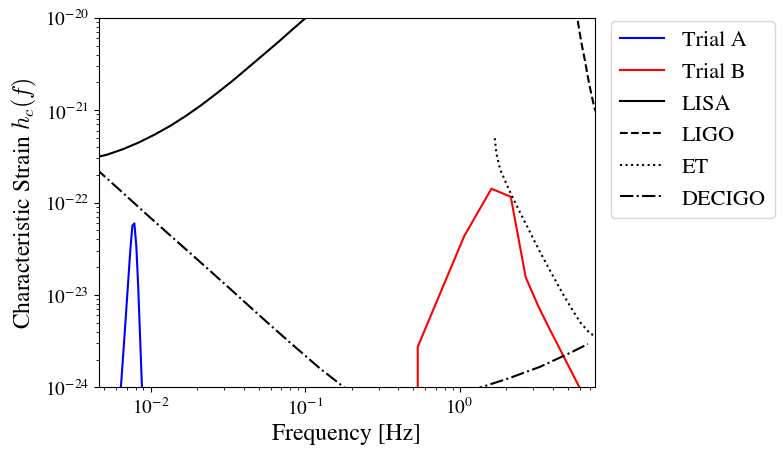

In [106]:
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})

plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["mathtext.rm"] = "serif"


plt.tick_params(axis='both', labelsize=14)

freq_high,hc_high=calc_hc('20251203_M_WD=1.4_M_NS=10.0_A=3.0_mode=Jeans.csv', return_hc=True)

#plt.loglog(freqs[h_char>max(h_char)/100], h_char[h_char>max(h_char)/100],c="b")
#plt.loglog(freq_high[np.logical_and(hc_high>max(hc_high)/100,freq_high<10)], 
#           hc_high[np.logical_and(hc_high>max(hc_high)/100,freq_high<10)],c="r")

plt.loglog(freqs, h_char,c="b",label="Trial A")

plt.loglog(np.append([freq_high[0]],freq_high), 
           np.append([0],hc_high),c="r",label="Trial B")

plt.loglog(LISA[::2],LISA[1::2],c="k",label="LISA")
plt.loglog(LIGO[::2],LIGO[1::2],c="k",linestyle="--",label="LIGO")
plt.loglog(ET[::2],ET[1::2],c="k",linestyle=":",label="ET")
plt.loglog(DECIGO[::2],DECIGO[1::2],linestyle="-.",label="DECIGO",c="k")

plt.xlim(x_limit_hc)
plt.ylim(1e-24,1e-20)
plt.legend(bbox_to_anchor=(1.01, 1.02), loc='upper left',fontsize=16)
plt.xlabel("Frequency [Hz]",size=17)
plt.ylabel("Characteristic Strain $h_c(f)$",size=17)
plt.savefig("Trial_A_B_hc_w_D.pdf", dpi=300, bbox_inches="tight")

In [76]:
,,print(freqs[h_char==max(h_char)][0], max(h_char))

0.007857934022834683 5.951094055360212e-23


In [77]:
try:
    from pycbc import psd
    # choose frequency grid that covers your freqs
    delta_f = freqs[1] - freqs[0]
    flen = int(max(freqs) // delta_f) + 1
    # pycbc expects flow (lowest freq) as a parameter; pick e.g. 1/4 or 10 Hz depending on interest
    flow = max(delta_f, 10.0)  # example; adjust to your data
    # generate aLIGO design PSD (Zero Detuned High Power)
    aligo_psd = psd.aLIGOZeroDetHighPower(flen, delta_f, flow)
    # build matching freq vector for the PSD
    f_psd = np.arange(0, flen) * delta_f + flow
    # convert to characteristic noise strain: h_n = sqrt(f * S_n(f))
    # be careful: aligo_psd is one-sided PSD (S_n in strain^2/Hz)
    h_n_aligo = np.sqrt(f_psd * aligo_psd)
except Exception as e:
    print("PyCBC not available or failed to build PSD:", e)
    aligo_psd = None

PyCBC not available or failed to build PSD: No module named 'pycbc'
